In [1]:
from langchain.chat_models import init_chat_model




# openrouter model for subagents 
openrouter_model = init_chat_model(
    "openrouter:google/gemini-2.5-flash"
)

# groq model for deepagents
groq_model = init_chat_model(
    "groq:openai/gpt-oss-20b"
)

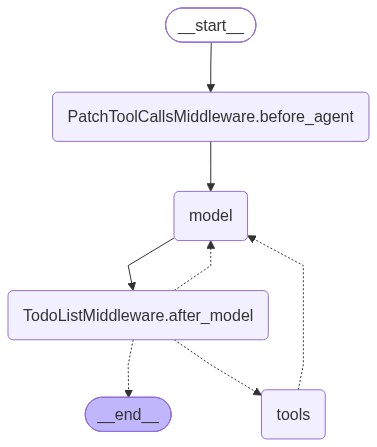

In [4]:
from langchain.tools import tool
from langchain.agents.middleware import TodoListMiddleware
from langchain_tavily import TavilySearch
from langchain.agents import create_agent

from deepagents import CompiledSubAgent, create_deep_agent
from deepagents.backends import StateBackend

from langgraph.checkpoint.memory import InMemorySaver
from typing import Dict, Any 

@tool
def web_search(query: str, max_results: int = 1,include_answer: bool = True, include_raw_content: bool = False)->Dict[str, Any]:
    """
    A Web searching tool
    returns a dictonary of results
    """
    tool = TavilySearch(
        max_results=max_results,
        topic="general",
        include_answer=include_answer,
        include_raw_content=include_raw_content,
        search_depth="basic",
    )
    return tool.invoke(query)

# create_agent returs a compiled graph
custom_graph = create_agent(
    model = openrouter_model,
    system_prompt="You are a data analysis specialist. Use available tools when necessary.",
    tools=[web_search]
)


# wrap the compiled graph to assign its name, description and runnable graph anf communication between subagents and deepagents
subagent = CompiledSubAgent(
    name="data-analyzer",
    description="MANDATORY for any market research, pricing metrics, cost lookups, or competitive analysis tasks. Analyzes numerical data, performs calculations",
    runnable=custom_graph
)


# register with create_deepagent
deepagent = create_deep_agent(
    model=groq_model,
    backend=StateBackend(),
    checkpointer=InMemorySaver(),
    subagents=[subagent],
    middleware=[TodoListMiddleware()],
    system_prompt=(
        "You are a strict task coordinator. You possess no internal research capabilities.\n\n"
        "WORKFLOW RULES:\n"
        "1. BEFORE doing anything else, you MUST use the `write_todos` tool to write out a todo list for the user's request.\n"
        "2. For any request regarding market analysis, costs, or domain research, you MUST call the `task()` tool with subagent_type='data-analyzer'.\n"
        "3. Once the subagent tool returns a result, update the todo item to completed using `write_todos` and relay the EXACT response directly to the user without adding supplementary figures."
    )
)  
deepagent

In [ ]:
resp = deepagent.invoke({
    'messages': "Reserach about LLM Gateways and provide me a detailed summary."
},config={
    "configurable":{
        "thread_id": "sub-1"
        
    }
}
)

In [ ]:
for m in resp["messages"]:
    m.pretty_print()

In [ ]:
# Test the worker independently
worker_result = custom_graph.invoke({
    "messages": [
        {
            "role": "user",
            "content": (
                "Research LLM Gateways. "
                "Explain their architecture, benefits, "
                "limitations and popular implementations."
            )
        }
    ]
})

# Inspect the actual messages
for message in worker_result["messages"]:
    print("\nType:", type(message).__name__)
    print("Content:", message.content)

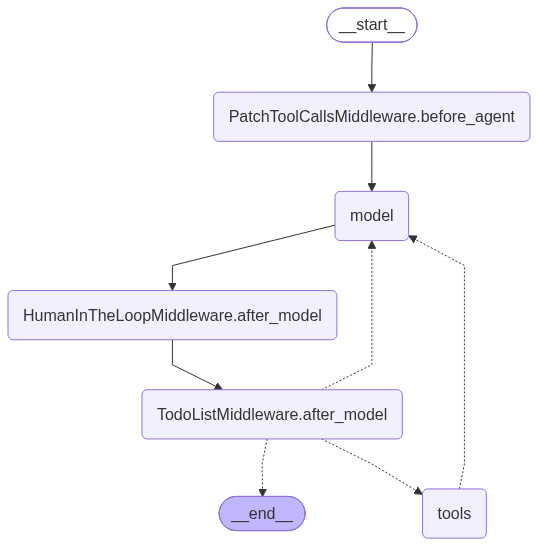

In [8]:
from pydantic import BaseModel, Field, HttpUrl
from deepagents import create_deep_agent
from langchain.agents.middleware import TodoListMiddleware

class ResearchFindings(BaseModel):
    """Structured Findings for research tasks"""
    summary: str = Field(description="Summary of findings")
    confidence: float = Field(description="confidence Score from 0 to 1")
    sources: list[HttpUrl] = Field(min_length=3, description="List of source URL's")
   

research_subagent_dict = {
    "name": "researcher",
    "description": "Research the given topic and return structured results",
    "system_prompt": """Research the given topic throughly and return your findings
    You MUST format your final response strictly as a JSON object matching this schema:
        {
            "summary": "string summary",
            "confidence": 0.95,
            "sources": ["https://example.com"]
        }
    """,
    "tools": [web_search],
    "model": groq_model
}

d_agent1 = create_deep_agent(
    model=groq_model,
    backend=StateBackend(),
    checkpointer=InMemorySaver(),
    name="deepagent",
    middleware=[TodoListMiddleware()],
    system_prompt="""
        You are a research coordinator responsible for delegating tasks and presenting findings.

        WORKFLOW:

        Create a todo list.

        Delegate research tasks.

        Inspect responses for sufficient evidence.

        Request investigation into missing gaps.

        Complete todos only after verifying results.

        RULES:

        Do not invent facts, statistics, claims, or citations.

        Preserve source URLs and evidence; distinguish verified facts from uncertain findings.

        Report insufficient research when limitations exist; do not assume completeness just because a subagent responded.
        """,
    subagents=[research_subagent_dict],
    interrupt_on={
        "write_file":{
            "allowed_decisions": ["approve", "reject", "edit"]
        }
    }
)
d_agent1

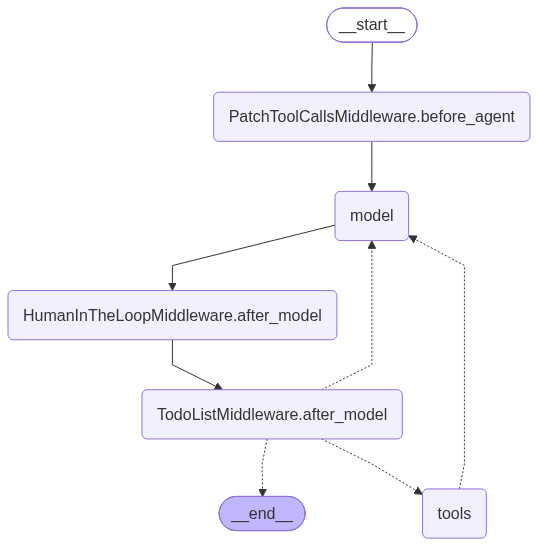

In [10]:
from pydantic import BaseModel, Field, HttpUrl
from deepagents import create_deep_agent
from langchain.agents.middleware import TodoListMiddleware
from langchain.tools import tool
import json

class ResearchFindings(BaseModel):
    """Structured Findings for research tasks"""
    summary: str = Field(description="Summary of findings")
    confidence: float = Field(description="confidence Score from 0 to 1")
    sources: list[HttpUrl] = Field(min_length=3, description="List of source URL's")
   
@tool(args_schema=ResearchFindings)
def submit_format(summary: str, confidence: float, sources: list[HttpUrl]):
    """
    Call this tool to submit your final structured response
    Must be complete after all research is complete and atleast 3 sources are gathered
    """
    validated_data = {
        'summary': summary,
        'confidence': confidence,
        'sources': [str(url) for url in sources]
    }
    return json.dump(validated_data)

groq_with_structured_response = groq_model.with_structured_output(ResearchFindings)
research_subagent_dict = {
    "name": "researcher",
    "description": "Research the given topic and return structured results",
    "system_prompt": """
        Research the given topic throughly and return your findings
        After the completion and before submission of result call 'submit_format' tool to submit the result of research
        Do not write your final answer as plain text; always finish by calling `submit_research_findings`.
    """,
    "tools": [web_search, submit_format],
    "model": groq_model
}

d_agent2 = create_deep_agent(
    model=groq_model,
    backend=StateBackend(),
    checkpointer=InMemorySaver(),
    name="deepagent",
    middleware=[TodoListMiddleware()],
    system_prompt="""
        You are a research coordinator responsible for delegating tasks and presenting findings.

        WORKFLOW:

        Create a todo list.

        Delegate research tasks.

        Inspect responses for sufficient evidence.

        Request investigation into missing gaps.

        Complete todos only after verifying results.

        RULES:

        Do not invent facts, statistics, claims, or citations.

        Preserve source URLs and evidence; distinguish verified facts from uncertain findings.

        Report insufficient research when limitations exist; do not assume completeness just because a subagent responded.
        """,
    subagents=[research_subagent_dict],
    interrupt_on={
        "write_file":{
            "allowed_decisions": ["approve", "reject", "edit"]
        }
    }
)
d_agent2

In [11]:
resp = d_agent2.invoke({
        'messages': "Reserach about LLM Gateways and provide me a detailed summary."
    },config={
        "configurable":{
            "thread_id": "a2"
            
        }
    }
)

RateLimitError: Error code: 429 - {'error': {'message': 'Rate limit reached for model `openai/gpt-oss-20b` in organization `org_01m5dbwaneeffr8jtfzg069hwe` service tier `on_demand` on tokens per minute (TPM): Limit 8000, Used 2832, Requested 6846. Please try again in 12.585s. Need more tokens? Upgrade to Dev Tier today at https://console.groq.com/settings/billing', 'type': 'tokens', 'code': 'rate_limit_exceeded'}}

In [ ]:
for m in resp["messages"]:
    m.pretty_print()

In [ ]:
config = {"configurable": {"thread_id": "1"}}
inputs = {"messages": "Research about LLM Gateways and provide me a detailed summary."}

for event in d_agent.stream(inputs, config=config, stream_mode="updates"):
    for node_name, node_output in event.items():
        print(f"\n--- Node: {node_name} ---")
        if isinstance(node_output, dict) and "messages" in node_output:
            if "messages" in node_output:
                latest_msg = node_output["messages"][-1]
                print(latest_msg.content)
        else:
            print(node_output)

In [ ]:
config = {"configurable": {"thread_id": "a2"}}
inputs = {"messages": "Create a file test.txt and write content 'hello'"}

for event in d_agent.stream(inputs, config=config, stream_mode="updates"):
    print(event)
    for node_name, node_output in event.items():
        # Skip nodes that produce no output state
        if not node_output or not isinstance(node_output, dict):
            continue

        if "messages" in node_output and node_output["messages"]:
            latest_msg = node_output["messages"][-1]
            
            # Print non-empty content
            if latest_msg.content:
                print(latest_msg.content)

{'PatchToolCallsMiddleware.before_agent': {'messages': [RemoveMessage(content='', additional_kwargs={}, response_metadata={}, id='__remove_all__'), HumanMessage(content="Create a file test.txt and write content 'hello'", additional_kwargs={}, response_metadata={}, id='1ad95570-2474-41d7-bc1f-de5a8cbbf4a8'), AIMessage(content='', additional_kwargs={'reasoning_content': "We need to create a file test.txt with content 'hello'. We should use write_file tool. The file path should be absolute. Let's assume root is /. So path /test.txt. We'll call write_file.", 'tool_calls': [{'id': 'fc_801a7803-3404-49e1-89d3-2124595a84aa', 'function': {'arguments': '{"content":"hello","file_path":"/test.txt"}', 'name': 'write_file'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 75, 'prompt_tokens': 3270, 'total_tokens': 3345, 'completion_time': 0.085603316, 'completion_tokens_details': {'reasoning_tokens': 45}, 'prompt_time': 0.246069941, 'prompt_tokens_details': None, 'que

In [ ]:
config = {"configurable": {"thread_id": "1"}}
inputs = {"messages": "delete file text.txt"}


res1 = d_agent.invoke(inputs, config)

for m in res1['messages']:
    m.pretty_print()

================================ Human Message =================================

Create a file test.txt and write content 'hello'
================================== Ai Message ==================================
Name: deepagent
Tool Calls:
  write_file (fc_1df14bd2-9403-4111-8a06-cbf7201edfc5)
 Call ID: fc_1df14bd2-9403-4111-8a06-cbf7201edfc5
  Args:
    content: hello
    file_path: /root/test.txt
================================= Tool Message =================================
Name: write_file

Tool call write_file with id fc_1df14bd2-9403-4111-8a06-cbf7201edfc5 did not complete - no result was recorded. It may have been cancelled or interrupted.
================================ Human Message =================================

Create a file text.txt and write content 'hello'
================================== Ai Message ==================================
Name: deepagent
Tool Calls:
  write_file (fc_a1c2f46f-9181-4ae2-a1a5-993f8154208a)
 Call ID: fc_a1c2f46f-9181-4ae2-a1a5-993f8154208a

In [50]:
if res1.get("__interrupt__"):  
    # Extract interrupt information
    interrupt_value = res1["__interrupt__"][0].value  
    action_requests = interrupt_value["action_requests"]
    review_configs = interrupt_value["review_configs"]

    # Create a lookup map from tool name to review config
    config_map = {cfg["action_name"]: cfg for cfg in review_configs}

    # Display the pending actions to the user
    for action in action_requests:
        review_config = config_map[action["name"]]
        print(f"Tool: {action['name']}")
        print(f"Arguments: {action['args']}")
        print(f"Allowed decisions: {review_config['allowed_decisions']}")


Tool: write_file
Arguments: {'content': 'hello', 'file_path': '/root/text.txt'}
Allowed decisions: ['approve', 'reject', 'edit']


In [53]:
from langgraph.types import Command
decisions = [
    {
        'type': 'approve',
        'message': 'accept the file creation operation'
    }
]
res2 = d_agent.invoke(
    Command(resume={'decisions': decisions}),
    config=config
)

In [54]:
res2

{'messages': [HumanMessage(content="Create a file test.txt and write content 'hello'", additional_kwargs={}, response_metadata={}, id='59001639-dfcf-4ac3-94c4-7eaf2a5e936b'),
  AIMessage(content='', additional_kwargs={'reasoning_content': "We need to create a file test.txt with content 'hello'. The file path must be absolute. We are in a container; likely root or some working directory. The tool write_file requires absolute path. We need to find a suitable absolute path. Usually, the environment root is /root or /workspace. Let's use /tmp/test.txt? But better to use /root/test.txt. The assistant can use write_file. We'll do that.", 'tool_calls': [{'id': 'fc_1df14bd2-9403-4111-8a06-cbf7201edfc5', 'function': {'arguments': '{"content":"hello","file_path":"/root/test.txt"}', 'name': 'write_file'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 121, 'prompt_tokens': 3270, 'total_tokens': 3391, 'completion_time': 0.129287292, 'completion_tokens_details': {'re